# [Lab Session 4](deconvolution.ipynb)

In [7]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

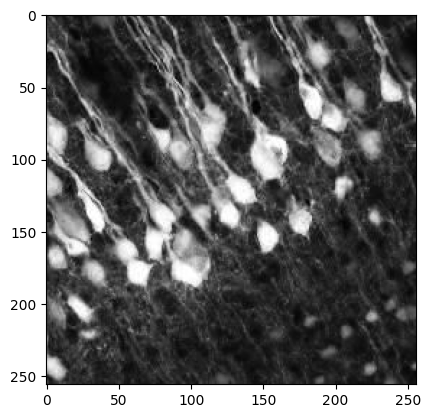

In [3]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

In [8]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2
#point_spread_function = scipy.signal.convolve2d(img, psf, mode='same',
#boundary='symm') 
point_spread_function = conv(img, psf, mode='same',
boundary='symm') 

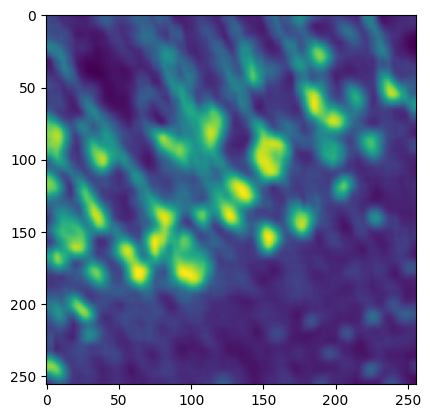

In [9]:
plt.figure()
plt.imshow(point_spread_function)

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

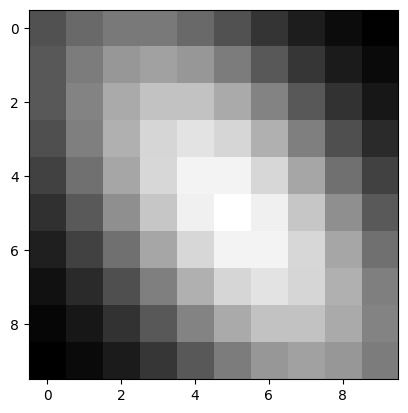

In [10]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

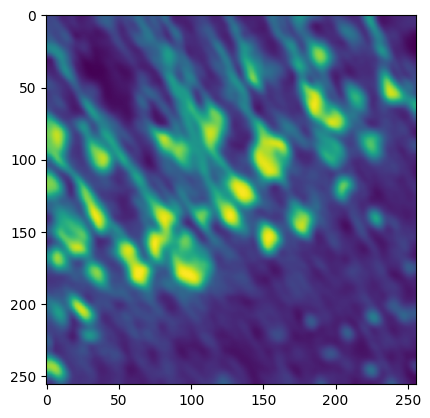

In [11]:
gaussian = create_psf(psf_size)
second_psf_img = conv(img, gaussian, mode='same',
boundary='symm') 
plt.figure()
plt.imshow(second_psf_img)

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [18]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5) 
    P2 = np.flip(psf)
    for x in range(n_iterations):
        Nenner= conv(img_deconv, psf, mode='same', boundary='symm') 
        Bruch = image / (Nenner)
        Klammer = conv(Bruch, P2, mode='same', boundary='symm') 
        img_deconv = img_deconv * Klammer 
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [24]:
deconv_img = richardson_lucy_deconvolution(point_spread_function, psf, 10)

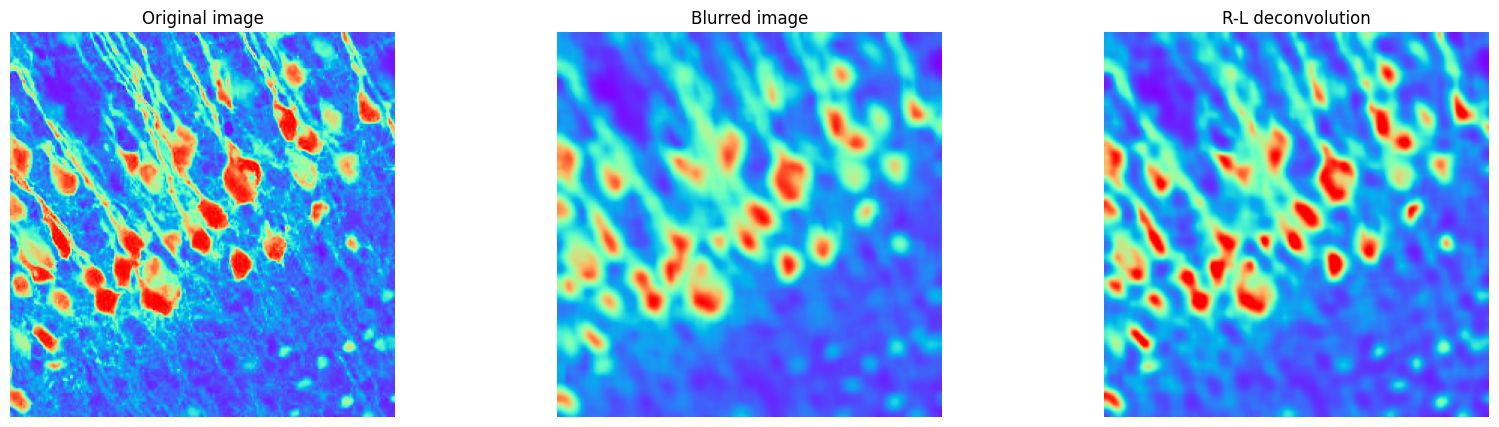

In [25]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'rainbow')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(point_spread_function, 'rainbow')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconv_img, 'rainbow')
plt.title('R-L deconvolution')
plt.show()

weniger ist actually besser

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [26]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

In [28]:
white_noise_machen = conv(img, noise, mode='same', boundary='symm')
white_noise_machen = white_noise_machen.clip(0,1)
white_noise_retten = richardson_lucy_deconvolution(white_noise_machen, noise, 10)
plt.figure(figsize=(20,5))
plt.subplot(1, 2, 1)
plt.axis('off')
plt.imshow(white_noise_machen, 'rainbow')
plt.title('white_noise_machene')
plt.subplot(1, 2, 2)
plt.axis('off')
plt.imshow(white_noise_retten, 'rainbow')
plt.title('white_noise_retten')

KeyboardInterrupt: 

In [ ]:
white_noise_machen = img + noise
white_noise_machen = white_noise_machen.clip(0,1)
white_noise_retten = richardson_lucy_deconvolution(white_noise_machen, noise, 10)
plt.figure(figsize=(20,5))
plt.subplot(1, 2, 1)
plt.axis('off')
plt.imshow(white_noise_machen, 'rainbow')
plt.title('white_noise_machene')
plt.subplot(1, 2, 2)
plt.axis('off')
plt.imshow(white_noise_retten, 'rainbow')
plt.title('white_noise_retten')

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

**[Task 8.]()** Use a wrong PSF to restore the image